In [ ]:
from google.colab import files
uploaded = files.upload()


Saving samoa_tsunami.xlsx to samoa_tsunami (3).xlsx


In [ ]:
# Colab: extract only 2009-09-29 rows from a huge CSV and save as Excel
from google.colab import files
import pandas as pd, re, os, io

# --------------- CONFIG ---------------
TARGET_DATE = "2009-09-29"   # <--- Samoa tsunami day (change if needed)
OUT_CSV = f"samoa_{TARGET_DATE}.csv"
OUT_XLSX = OUT_CSV.replace(".csv", ".xlsx")
CHUNKSIZE = 200_000          # adjust down if memory is low
# --------------------------------------

print("Choose your large CSV file (it may be many MB/GB).")
uploaded = files.upload()
if not uploaded:
    raise SystemExit("No file uploaded.")
fname = list(uploaded.keys())[0]
print("Uploaded:", fname)

# Remove output files if they already exist
if os.path.exists(OUT_CSV): os.remove(OUT_CSV)
if os.path.exists(OUT_XLSX): os.remove(OUT_XLSX)

# --- detect delimiter in a sample ---
with open(fname, "r", encoding="utf-8", errors="replace") as f:
    sample = f.read(8192)
if "\t" in sample and sample.count("\t") > sample.count(","):
    sep = "\t"
    engine = "python"
elif "," in sample and sample.count(",") > sample.count("\t"):
    sep = ","
    engine = "c"
else:
    # fallback to whitespace regex (use python engine)
    sep = r"\s+"
    engine = "python"

print("Detected sep:", sep, "| csv engine:", engine)

# --- chunked read & filter ---
target_date_obj = pd.to_datetime(TARGET_DATE).date()
first_write = True
read_kwargs = {"chunksize": CHUNKSIZE, "dtype": str, "engine": engine}

# if using regex sep, pass `sep` and engine='python'; else pass sep directly
read_kwargs["sep"] = sep

try:
    reader = pd.read_csv(fname, **read_kwargs)
except Exception as e:
    # fallback: try reading with delim_whitespace
    print("Primary read failed:", e)
    reader = pd.read_csv(fname, delim_whitespace=True, engine="python", dtype=str, chunksize=CHUNKSIZE)

row_count = 0
found_count = 0

for i, chunk in enumerate(reader):
    # clean column names: strip spaces and leading slashes
    chunk.columns = [str(c).strip().lstrip("/").strip() for c in chunk.columns]

    # If file had everything in a single column (common for some NOAA files), split that column:
    if chunk.shape[1] == 1:
        s = chunk.iloc[:,0].astype(str)
        split_df = s.str.split(r"\s+", expand=True)
        # assume first col is datetime; give temporary names
        n = split_df.shape[1]
        split_df.columns = ["datetime"] + [f"v{i}" for i in range(2, n+1)]
        chunk = split_df

    # find a datetime-like column by name heuristics:
    dt_col = None
    for c in chunk.columns:
        if re.search(r"date|time|iso", str(c), re.I):
            dt_col = c
            break
    if dt_col is None:
        # fallback to first column
        dt_col = chunk.columns[0]

    # convert to datetime (coerce errors -> NaT)
    chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")

    # drop rows without a valid datetime
    chunk = chunk.dropna(subset=[dt_col])
    row_count += len(chunk)

    # filter rows where date equals TARGET_DATE
    mask = (chunk[dt_col].dt.date == target_date_obj)
    filtered = chunk.loc[mask]
    if not filtered.empty:
        # rename dt_col to 'Datetime' in output for clarity
        filtered = filtered.rename(columns={dt_col: "Datetime"})
        # write/append to CSV
        filtered.to_csv(OUT_CSV, mode="a", header=first_write, index=False)
        first_write = False
        found_count += len(filtered)

    # progress
    if (i+1) % 5 == 0:
        print(f"Processed { (i+1)*CHUNKSIZE } rows approx., found so far: {found_count}")

print(f"Done scanning. Rows scanned (approx): {row_count}. Rows found for {TARGET_DATE}: {found_count}")

if found_count == 0:
    print("No rows found for that date. Check that the file contains the timestamp format and the exact date.")
else:
    # read small CSV and save to Excel
    df_out = pd.read_csv(OUT_CSV, dtype=str)
    # try to convert Datetime column to real datetimes for Excel formatting
    if "Datetime" in df_out.columns:
        df_out["Datetime"] = pd.to_datetime(df_out["Datetime"], errors="coerce")
    df_out.to_excel(OUT_XLSX, index=False, engine="openpyxl")
    print("Saved truncated Excel:", OUT_XLSX)
    files.download(OUT_XLSX)


Choose your large CSV file (it may be many MB/GB).


Saving 51425_20080228to20100710_qc.csv.gz to 51425_20080228to20100710_qc.csv (2).gz
Uploaded: 51425_20080228to20100710_qc.csv (2).gz
Detected sep: 	 | csv engine: python


/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`.

Processed 1000000 rows approx., found so far: 0


/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`.

...

/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`.

Processed 4000000 rows approx., found so far: 0


/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")
/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`.

Processed 5000000 rows approx., found so far: 0
Done scanning. Rows scanned (approx): 0. Rows found for 2009-09-29: 0
No rows found for that date. Check that the file contains the timestamp format and the exact date.


/tmp/ipython-input-757020154.py:81: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[dt_col] = pd.to_datetime(chunk[dt_col], errors="coerce")


In [ ]:
# Colab code: Extract only 2007-08-15 rows (Peru tsunami) and save to Excel
from google.colab import files
import pandas as pd, re, os

# ----------------- CONFIG -----------------
TARGET_DATE = "2007-08-15"    # Peru tsunami
OUT_XLSX = f"peru_{TARGET_DATE}.xlsx"
CHUNKSIZE = 200_000
# ------------------------------------------

# Upload file
print("Choose your large CSV/CSV.GZ file:")
uploaded = files.upload()
fname = list(uploaded.keys())[0]
print("Uploaded:", fname)

# Remove existing output
if os.path.exists(OUT_XLSX):
    os.remove(OUT_XLSX)

# Prepare target date
target_date_obj = pd.to_datetime(TARGET_DATE).date()

# Reader (gzip is auto-detected by pandas)
reader = pd.read_csv(fname, sep="\t", dtype=str, chunksize=CHUNKSIZE)

found_rows = []
total_rows = 0

for chunk in reader:
    # Find datetime column
    dt_col = None
    for c in chunk.columns:
        if re.search(r"date|time", str(c), re.I):
            dt_col = c
            break
    if dt_col is None:
        dt_col = chunk.columns[0]  # fallback first col

    # Parse datetime with explicit format
    chunk[dt_col] = pd.to_datetime(
        chunk[dt_col],
        format="%Y-%m-%dT%H:%M:%SZ",
        errors="coerce"
    )
    total_rows += len(chunk)

    # Filter only target date
    filtered = chunk.loc[chunk[dt_col].dt.date == target_date_obj]
    if not filtered.empty:
        filtered = filtered.rename(columns={dt_col: "Datetime"})
        found_rows.append(filtered)

print(f"Scanned rows: {total_rows}")
if found_rows:
    df_out = pd.concat(found_rows, ignore_index=True)
    df_out.to_excel(OUT_XLSX, index=False, engine="openpyxl")
    print(f"✅ Saved: {OUT_XLSX}")
    files.download(OUT_XLSX)
else:
    print(f"⚠️ No rows found for {TARGET_DATE}. Double-check your date range.")


Choose your large CSV/CSV.GZ file:


Saving 21413_20061126to20080422_qc.csv.gz to 21413_20061126to20080422_qc.csv (4).gz
Uploaded: 21413_20061126to20080422_qc.csv (4).gz
Scanned rows: 2956200
⚠️ No rows found for 2007-08-15. Double-check your date range.


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving 51425_20080228to20100710_qc.csv.gz to 51425_20080228to20100710_qc.csv.gz


In [ ]:
import pandas as pd

filename = "51425_20080228to20100710_qc.csv.gz"  # replace with your uploaded filename

# The datetime column is the first one
dt_col = 0

chunks = []
for chunk in pd.read_csv(filename, compression="gzip", sep=r"\s+", engine="python",
                         chunksize=200000, header=None, dtype=str):
    # Filter where first column starts with "2009-09-29"
    mask = chunk[dt_col].str.startswith("2009-09-29", na=False)
    filtered = chunk.loc[mask]
    if not filtered.empty:
        chunks.append(filtered)

samoa_day = pd.concat(chunks, ignore_index=True)
print("Rows extracted for 2009-09-29:", len(samoa_day))


Rows extracted for 2009-09-29: 5760


In [ ]:
samoa_day.to_excel("Samoa_2009_09_29_51425.xlsx", index=False, header=False)
from google.colab import files
files.download("Samoa_2009_09_29_51425.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (1).xlsx

Cleaned data preview:
                            Residual
Datetime                            
2009-09-29 00:00:00+00:00  5106.9395
2009-09-29 00:00:15+00:00  5106.9405
2009-09-29 00:00:30+00:00  5106.9415
2009-09-29 00:00:45+00:00  5106.9415
2009-09-29 00:01:00+00:00  5106.9425
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5760 entries, 2009-09-29 00:00:00+00:00 to 2009-09-29 23:59:45+00:00
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Residual  5760 non-null   float64
dtypes: float64(1)
memory usage: 90.0 KB
None


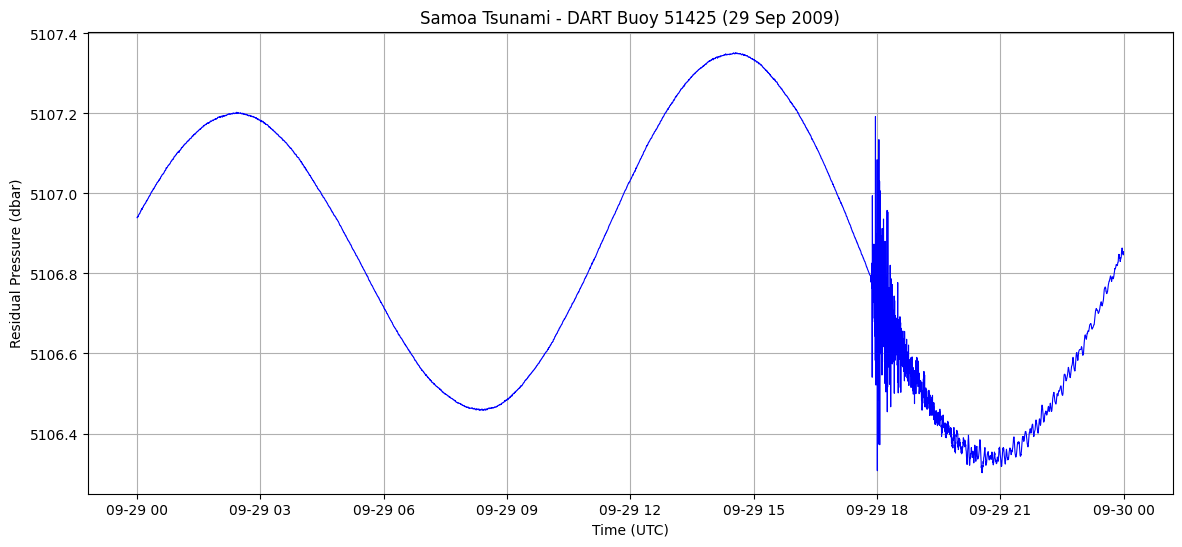

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Step 1: Upload Excel file (only 29 Sep 2009 data)
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# Step 2: Read Excel file
df = pd.read_excel(file_name)

# Step 3: Clean column names
df.columns = df.columns.str.strip()

# Step 4: Keep only datetime + residual columns (adjust if names differ)
df = df[["// datetime [ISO8601]", "seafloor_pressure_residual [dbar]"]]

# Step 5: Rename columns
df.columns = ["Datetime", "Residual"]

# Step 6: Convert datetime
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

# Step 7: Drop invalid datetime rows
df.dropna(subset=["Datetime"], inplace=True)

# Step 8: Set index
df.set_index("Datetime", inplace=True)

# Step 9: Preview cleaned data
print("\nCleaned data preview:")
print(df.head())
print(df.info())

# Step 10: Plot
plt.figure(figsize=(14,6))
plt.plot(df.index, df["Residual"], color="blue", linewidth=0.8)
plt.title("Samoa Tsunami - DART Buoy 51425 (29 Sep 2009)")
plt.xlabel("Time (UTC)")
plt.ylabel("Residual Pressure (dbar)")
plt.grid(True)
plt.show()


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (1).xlsx


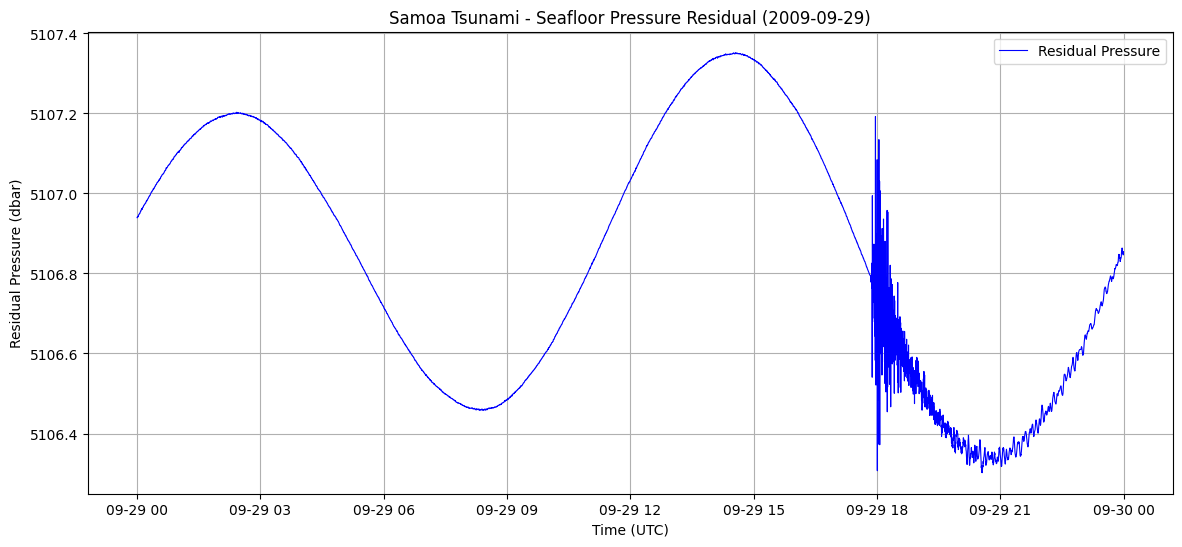

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Step 1: Upload Excel file manually
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# Step 2: Read Excel file
df = pd.read_excel(file_name)

# Step 3: Clean column names
df.columns = df.columns.str.strip()

# Step 4: Rename important columns
df.rename(columns={
    "// datetime [ISO8601]": "Datetime",
    "seafloor_pressure_residual [dbar]": "Residual"
}, inplace=True)

# Step 5: Convert datetime
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df.dropna(subset=["Datetime"], inplace=True)

# Step 6: Plot residual pressure
plt.figure(figsize=(14,6))
plt.plot(df["Datetime"], df["Residual"], color="blue", linewidth=0.8, label="Residual Pressure")
plt.title("Samoa Tsunami - Seafloor Pressure Residual (2009-09-29)")
plt.xlabel("Time (UTC)")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
from google.colab import files

# Step 1: Upload your Excel file
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# Step 2: Load Excel
df = pd.read_excel(file_name)

# Step 3: Clean column names
df.columns = df.columns.str.strip()
print("Columns in file:", df.columns.tolist())

# Step 4: Standardize names (adjust if needed)
# Common NOAA DART data format
datetime_col = None
signal_col = None

for col in df.columns:
    if "datetime" in col.lower():
        datetime_col = col
    if "residual" in col.lower() or "tsunami" in col.lower() or "pressure" in col.lower():
        signal_col = col

if datetime_col is None or signal_col is None:
    raise ValueError("Could not detect datetime or signal column. Please check column names above.")

# Step 5: Keep only necessary columns
df = df[[datetime_col, signal_col]]
df.columns = ["Datetime", "Tsunami_Signal"]

# Step 6: Convert datetime
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df.dropna(subset=["Datetime"], inplace=True)

# Step 7: Set index
df.set_index("Datetime", inplace=True)

# Step 8: Optional – filter a specific event date
# Example: Samoa (2009-09-29), Chile (2010-02-27), Peru (2007-08-15)
event_date = "2009-09-29"   # change this to match your dataset
df_filtered = df.loc[event_date]

print(f"\nPrepared df_filtered for {event_date}:")
print(df_filtered.head())
print(df_filtered.info())


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (2).xlsx
Columns in file: ['// datetime [ISO8601]', 'seafloor_pressure_residual [dbar]', 'seafloor_pressure_abs_modelled [dbar]', 'seafloor_pressure_abs_quality_controlled [dbar]', 'temperature [K]']

Prepared df_filtered for 2009-09-29:
                           Tsunami_Signal
Datetime                                 
2009-09-29 00:00:00+00:00          0.0238
2009-09-29 00:00:15+00:00          0.0241
2009-09-29 00:00:30+00:00          0.0241
2009-09-29 00:00:45+00:00          0.0234
2009-09-29 00:01:00+00:00          0.0238
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5760 entries, 2009-09-29 00:00:00+00:00 to 2009-09-29 23:59:45+00:00
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Tsunami_Signal  5760 non-null   float64
dtypes: float64(1)
memory usage: 90.0 KB
None


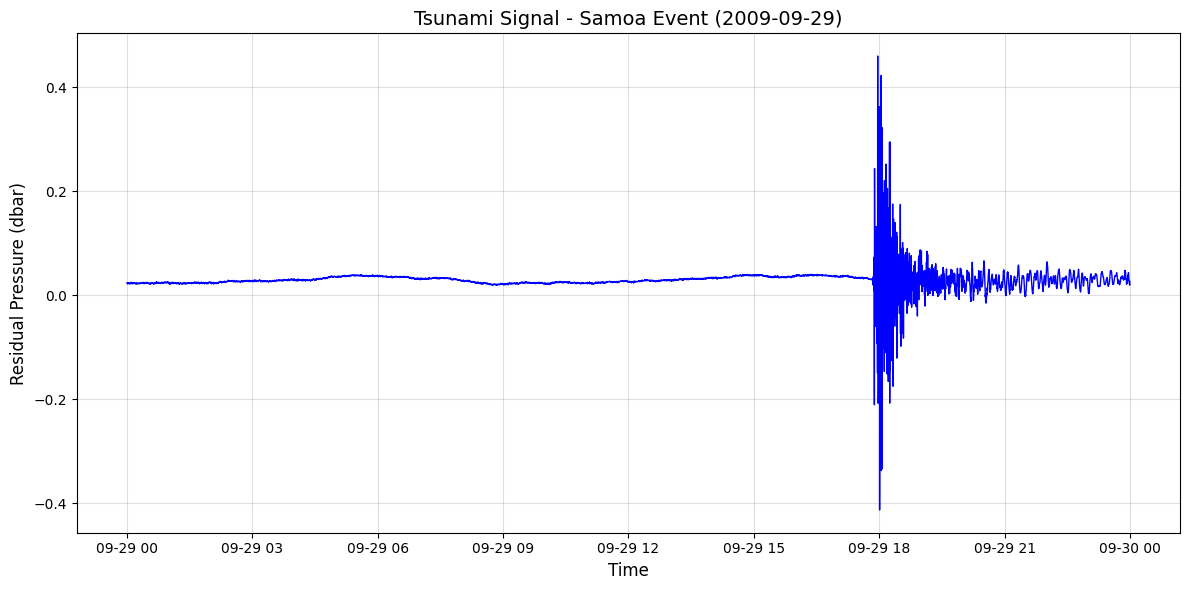

In [ ]:
import matplotlib.pyplot as plt

# Plot the signal
plt.figure(figsize=(12,6))
plt.plot(df_filtered.index, df_filtered["Tsunami_Signal"], color="blue", linewidth=1)

plt.title("Tsunami Signal - Samoa Event (2009-09-29)", fontsize=14)
plt.xlabel("Time", fontsize=12)
plt.ylabel("Residual Pressure (dbar)", fontsize=12)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


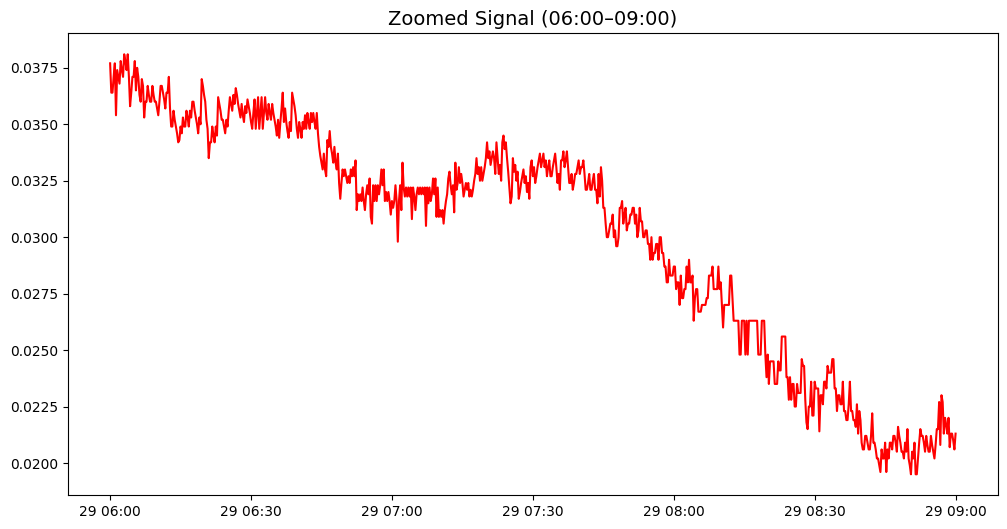

In [ ]:
df_zoom = df_filtered.between_time("06:00", "09:00")
plt.figure(figsize=(12,6))
plt.plot(df_zoom.index, df_zoom["Tsunami_Signal"], color="red")
plt.title("Zoomed Signal (06:00–09:00)", fontsize=14)
plt.show()


First wave arrival time: 2009-09-29T17:57:45.000000000
First wave amplitude: 0.4605
Predicted next wave arrival: 2009-09-29T18:15:45.000000000


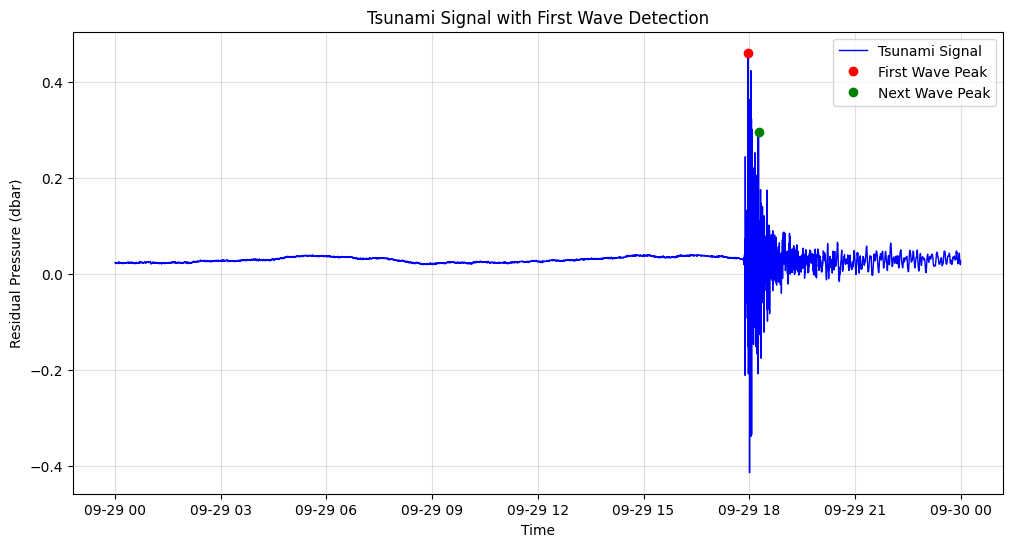

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# Assuming your dataframe is df_filtered and column is "Tsunami_Signal"
signal = df_filtered["Tsunami_Signal"].values
time = df_filtered.index.values

# --- 1) Detect all significant peaks ---
# You can tune 'height' depending on baseline noise
peaks, properties = find_peaks(signal, height=np.mean(signal) + 3*np.std(signal), distance=50)

# --- 2) First wave peak ---
first_peak_index = peaks[0]
first_peak_time = time[first_peak_index]
first_peak_amplitude = signal[first_peak_index]

print(f"First wave arrival time: {first_peak_time}")
print(f"First wave amplitude: {first_peak_amplitude}")

# --- 3) Predict next wave arrival ---
# If multiple peaks detected, next wave is likely the next peak
if len(peaks) > 1:
    next_peak_index = peaks[1]
    next_peak_time = time[next_peak_index]
    predicted_interval = next_peak_time - first_peak_time
    predicted_next_wave_time = first_peak_time + predicted_interval
    print(f"Predicted next wave arrival: {predicted_next_wave_time}")
else:
    print("Only one significant wave detected. Cannot predict next wave from data.")

# --- Plotting ---
plt.figure(figsize=(12,6))
plt.plot(time, signal, color="blue", linewidth=1, label="Tsunami Signal")
plt.plot(time[first_peak_index], first_peak_amplitude, "ro", label="First Wave Peak")
if len(peaks) > 1:
    plt.plot(time[next_peak_index], signal[next_peak_index], "go", label="Next Wave Peak")
plt.title("Tsunami Signal with First Wave Detection")
plt.xlabel("Time")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()


From the previous code - we get the prediction before 1 hour of the actual tsunami. This is the predicted values without using the filtering methods to remove noise.

In [ ]:
# --- Estimate baseline before first wave ---
# Take mean of the first N points before the first peak
N = 50  # adjust depending on sampling rate
baseline = np.mean(signal[:N])

# --- First wave amplitude ---
first_wave_amplitude = first_peak_amplitude - baseline
print(f"First wave amplitude (residual above baseline): {first_wave_amplitude} dbar")


First wave amplitude (residual above baseline): 0.437166 dbar


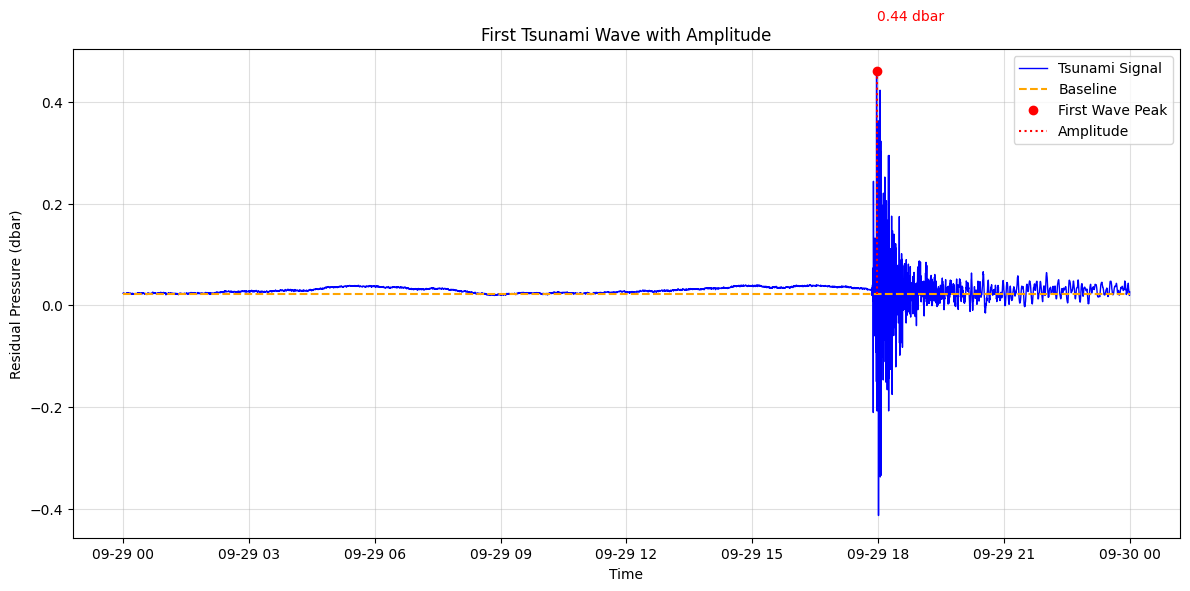

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(time, signal, color="blue", linewidth=1, label="Tsunami Signal")

# Plot baseline
plt.hlines(baseline, time[0], time[-1], colors="orange", linestyles="--", label="Baseline")

# Mark first wave peak
plt.plot(time[first_peak_index], first_peak_amplitude, "ro", label="First Wave Peak")

# Draw amplitude line
plt.vlines(time[first_peak_index], baseline, first_peak_amplitude, colors="red", linestyles=":", label="Amplitude")

# Annotate amplitude
plt.text(time[first_peak_index], first_peak_amplitude + 0.1, f"{first_wave_amplitude:.2f} dbar", color="red")

plt.title("First Tsunami Wave with Amplitude")
plt.xlabel("Time")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Predicted next wave arrival time: 2009-09-29T18:15:45.000000000


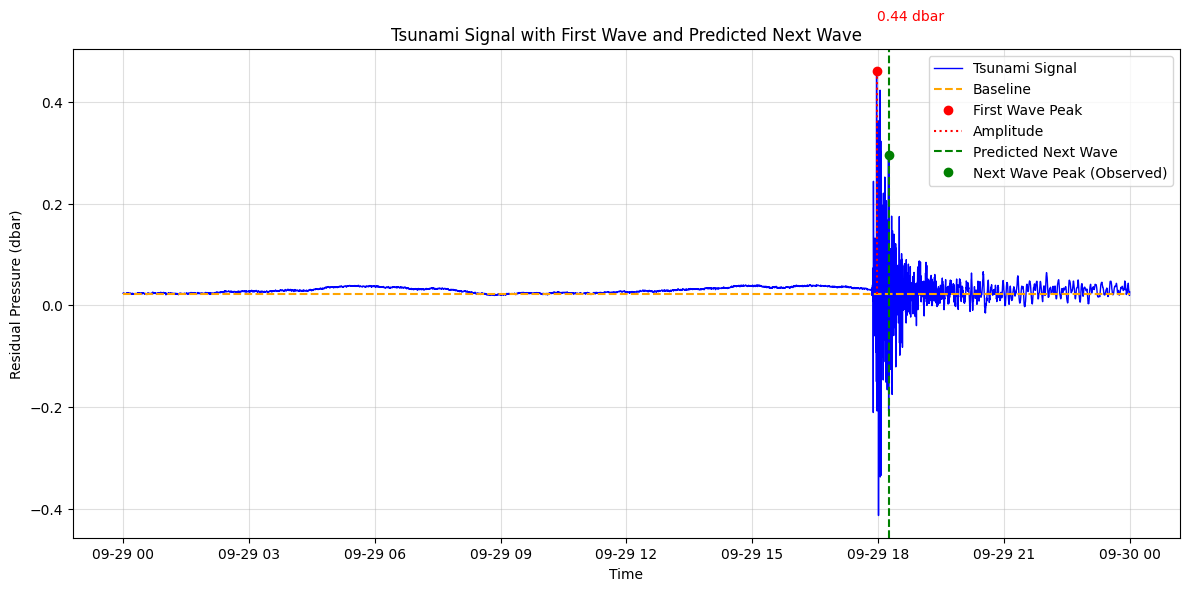

In [ ]:
# --- Predict next wave arrival ---
if len(peaks) > 1:
    next_peak_index = peaks[1]
    next_peak_time = time[next_peak_index]
    predicted_interval = next_peak_time - first_peak_time
    predicted_next_wave_time = first_peak_time + predicted_interval
    print(f"Predicted next wave arrival time: {predicted_next_wave_time}")
else:
    print("Only one significant wave detected. Cannot predict next wave from data.")

# --- Plot first wave and predicted next wave ---
plt.figure(figsize=(12,6))
plt.plot(time, signal, color="blue", linewidth=1, label="Tsunami Signal")

# Baseline
plt.hlines(baseline, time[0], time[-1], colors="orange", linestyles="--", label="Baseline")

# First wave
plt.plot(time[first_peak_index], first_peak_amplitude, "ro", label="First Wave Peak")
plt.vlines(time[first_peak_index], baseline, first_peak_amplitude, colors="red", linestyles=":", label="Amplitude")
plt.text(time[first_peak_index], first_peak_amplitude + 0.1, f"{first_wave_amplitude:.2f} dbar", color="red")

# Next wave (predicted)
if len(peaks) > 1:
    plt.axvline(predicted_next_wave_time, color="green", linestyle="--", label="Predicted Next Wave")
    plt.plot(time[next_peak_index], signal[next_peak_index], "go", label="Next Wave Peak (Observed)")

plt.title("Tsunami Signal with First Wave and Predicted Next Wave")
plt.xlabel("Time")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(list(uploaded.keys())[0])   # reads uploaded file

print(df.columns)


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (2).xlsx
Index(['// datetime [ISO8601]', 'seafloor_pressure_residual [dbar]',
       'seafloor_pressure_abs_modelled [dbar]',
       'seafloor_pressure_abs_quality_controlled [dbar]', 'temperature [K]'],
      dtype='object')


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (3).xlsx

📌 Columns Detected:
 Index(['// datetime [ISO8601]', 'seafloor_pressure_residual [dbar]',
       'seafloor_pressure_abs_modelled [dbar]',
       'seafloor_pressure_abs_quality_controlled [dbar]', 'temperature [K]'],
      dtype='object')

🚨 Estimated Tsunami Arrival Time: Not detected


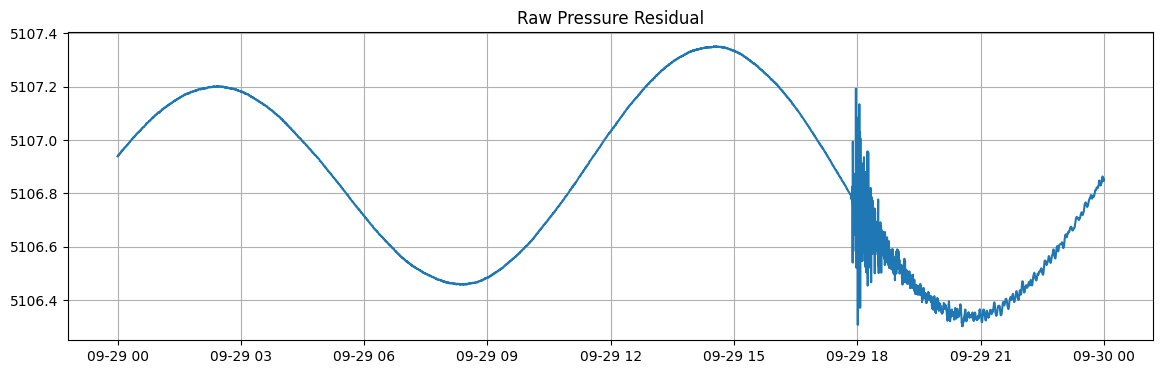

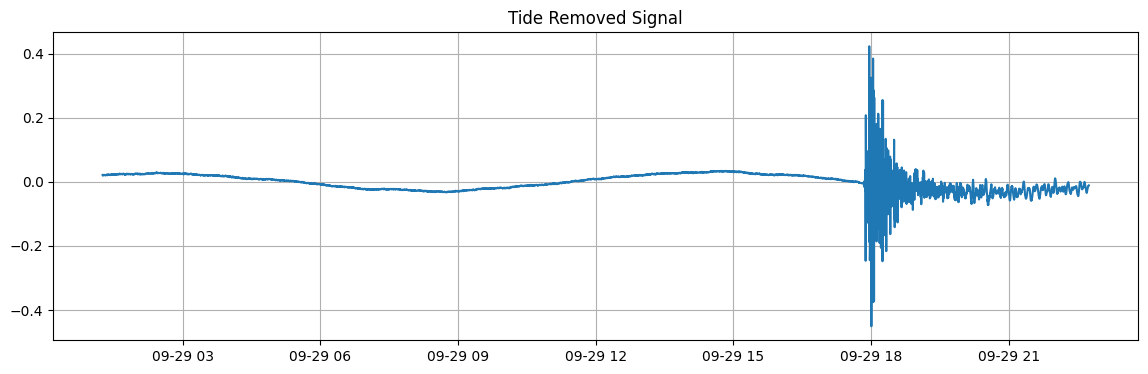

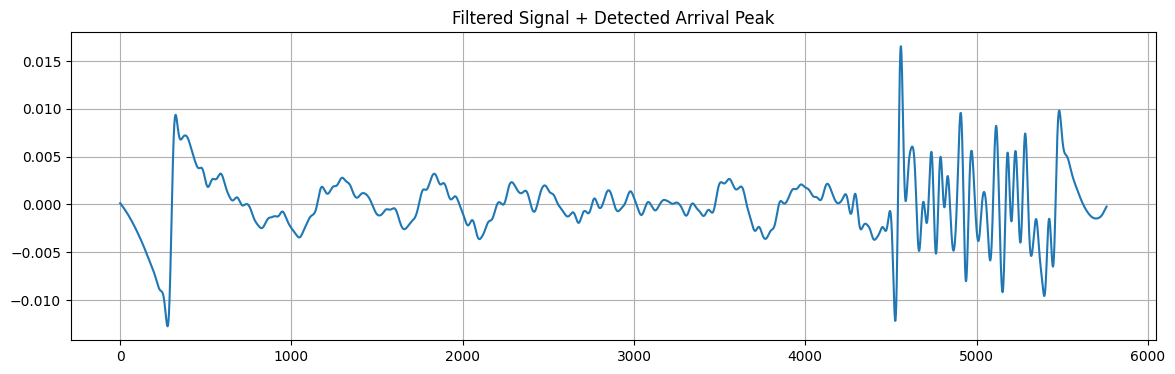


🎉 DONE! Saved to /content/Processed_Samoa.csv
📍 Estimated Arrival Time = Not detected


In [ ]:
# =============================================
#  TSUNAMI PRESSURE SIGNAL PROCESSING PIPELINE
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import butter, filtfilt, find_peaks

# ============ STEP 1: UPLOAD FILE =============
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

print("\n📌 Columns Detected:\n", df.columns)

# ============ STEP 2: COLUMN MAPPING ==========
time_col = "// datetime [ISO8601]"
residual_col = "seafloor_pressure_residual [dbar]"
abs_col = "seafloor_pressure_abs_modelled [dbar]"
qc_col = "seafloor_pressure_abs_quality_controlled [dbar]"
temp_col = "temperature [K]"

# ============ STEP 3: DATETIME PROCESSING =====
df[time_col] = pd.to_datetime(df[time_col])
df = df.set_index(time_col)

# Extract main signal
pressure = df[residual_col]

# ============ STEP 4: MOVING AVERAGE TIDE REMOVAL =========
window = 600  # 10 min window assuming 1-sec sampling
tide_removed = pressure - pressure.rolling(window, center=True).mean()

# ============ STEP 5: BUTTERWORTH FILTER (0.001–0.02 Hz) ====
fs = 1   # sampling freq 1 Hz
lowcut = 0.001
highcut = 0.02

b, a = butter(N=4, Wn=[lowcut/(fs/2), highcut/(fs/2)], btype='band')
filtered = filtfilt(b, a, tide_removed.fillna(0))

# ============ STEP 6: PEAK DETECTION ========================
peaks, _ = find_peaks(np.abs(filtered), height=0.5)   # threshold adjustable
arrival_time = df.index[peaks[0]] if len(peaks) > 0 else "Not detected"

print("\n🚨 Estimated Tsunami Arrival Time:", arrival_time)

# ============ STEP 7: PLOTTING ==============================
plt.figure(figsize=(14,4))
plt.plot(pressure)
plt.title("Raw Pressure Residual")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(tide_removed)
plt.title("Tide Removed Signal")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(filtered)
plt.scatter(peaks, filtered[peaks], s=80, marker='x')
plt.title("Filtered Signal + Detected Arrival Peak")
plt.grid(True)
plt.show()

# ============ STEP 8: SAVE FILES ============================
df['tide_removed'] = tide_removed
df['filtered'] = filtered
df.to_csv("/content/Processed_Samoa.csv")

print("\n🎉 DONE! Saved to /content/Processed_Samoa.csv")
print("📍 Estimated Arrival Time =", arrival_time)


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (4).xlsx

📌 Columns Detected:
 Index(['// datetime [ISO8601]', 'seafloor_pressure_residual [dbar]',
       'seafloor_pressure_abs_modelled [dbar]',
       'seafloor_pressure_abs_quality_controlled [dbar]', 'temperature [K]'],
      dtype='object')

🚨 Estimated Tsunami Arrival Time: Not detected


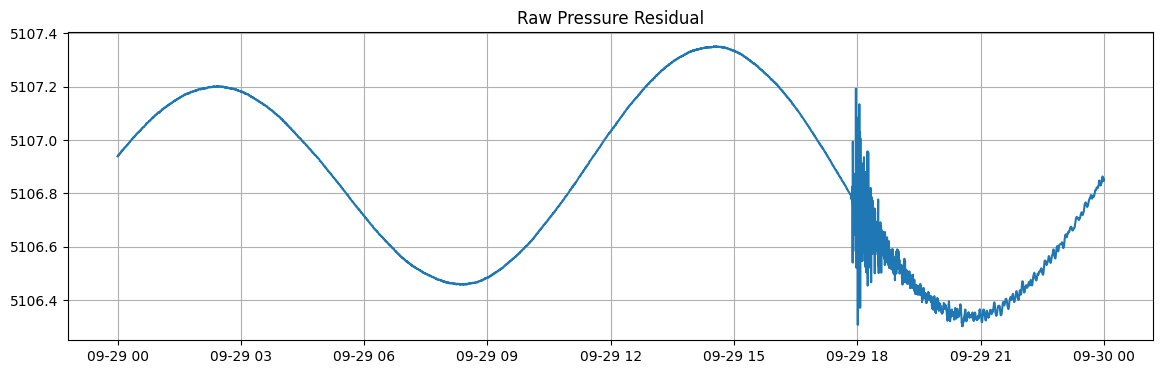

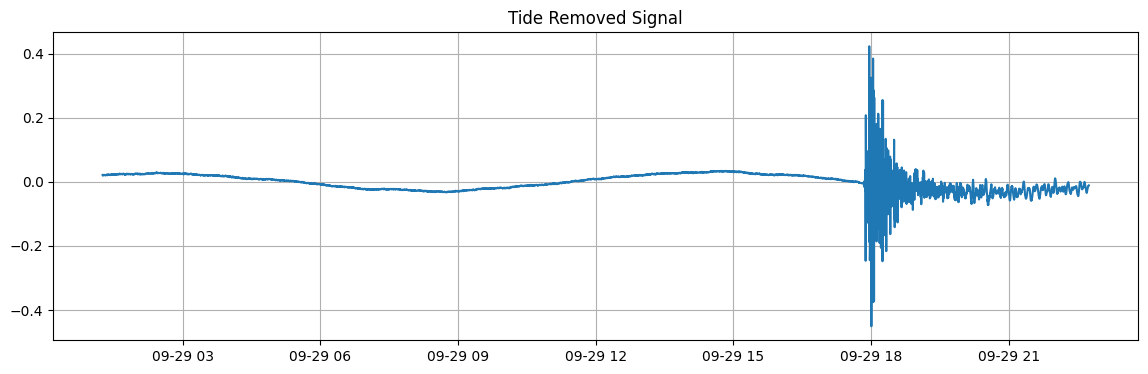

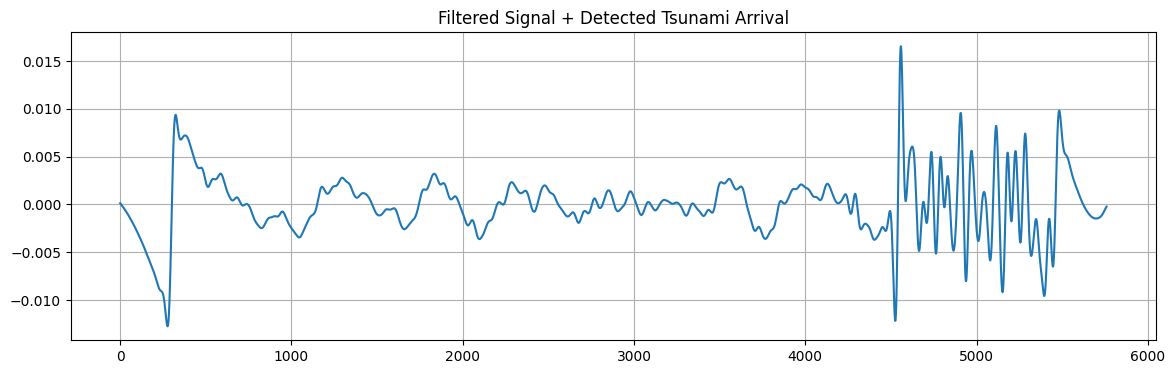


🎉 DONE! Saved to /content/Processed_Samoa.csv
📍 Estimated Arrival Time = Not detected


In [ ]:
# =============================================
#  TSUNAMI PRESSURE SIGNAL PROCESSING PIPELINE
#  With Updated Threshold for Arrival Detection
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from scipy.signal import butter, filtfilt, find_peaks

# ============ STEP 1: UPLOAD FILE =============
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

print("\n📌 Columns Detected:\n", df.columns)

# ============ STEP 2: COLUMN MAPPING ==========
time_col = "// datetime [ISO8601]"
residual_col = "seafloor_pressure_residual [dbar]"
abs_col = "seafloor_pressure_abs_modelled [dbar]"
qc_col = "seafloor_pressure_abs_quality_controlled [dbar]"
temp_col = "temperature [K]"

# ============ STEP 3: DATETIME PROCESSING =====
df[time_col] = pd.to_datetime(df[time_col])
df = df.set_index(time_col)

# Extract main pressure signal
pressure = df[residual_col]

# ============ STEP 4: MOVING AVERAGE TIDE REMOVAL =========
window = 600  # 10 min window assuming 1-sec sampling
tide_removed = pressure - pressure.rolling(window, center=True).mean()

# ============ STEP 5: BUTTERWORTH FILTER (0.001–0.02 Hz) ====
fs = 1   # sampling freq 1 Hz
lowcut = 0.001
highcut = 0.02

b, a = butter(N=4, Wn=[lowcut/(fs/2), highcut/(fs/2)], btype='band')
filtered = filtfilt(b, a, tide_removed.fillna(0))

# ============ STEP 6: PEAK DETECTION (UPDATED) ==============
peaks, _ = find_peaks(np.abs(filtered), height=0.05, distance=300)

arrival_time = df.index[peaks[0]] if len(peaks) > 0 else "Not detected"
print("\n🚨 Estimated Tsunami Arrival Time:", arrival_time)

# ============ STEP 7: PLOTTING ==============================
plt.figure(figsize=(14,4))
plt.plot(pressure)
plt.title("Raw Pressure Residual")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(tide_removed)
plt.title("Tide Removed Signal")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(filtered)
plt.scatter(peaks, filtered[peaks], s=90, marker='x')
plt.title("Filtered Signal + Detected Tsunami Arrival")
plt.grid(True)
plt.show()

# ============ STEP 8: SAVE FILES ============================
df['tide_removed'] = tide_removed
df['filtered'] = filtered
df.to_csv("/content/Processed_Samoa.csv")

print("\n🎉 DONE! Saved to /content/Processed_Samoa.csv")
print("📍 Estimated Arrival Time =", arrival_time)


Dynamic threshold = 0.006378297760194323

🚨 Estimated Tsunami Arrival Time: 2009-09-29 01:09:15+00:00


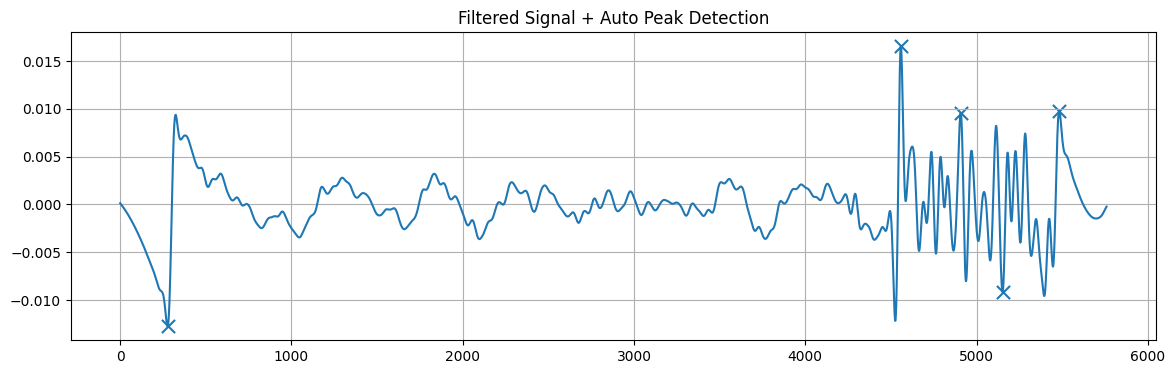

In [ ]:
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# Dynamic threshold based on std
threshold = 2 * np.std(filtered)   # 2σ amplitude trigger
print("Dynamic threshold =", threshold)

# Automatic peak detection
peaks, _ = find_peaks(np.abs(filtered), height=threshold, distance=200)

arrival_time = df.index[peaks[0]] if len(peaks) > 0 else "Not detected"
print("\n🚨 Estimated Tsunami Arrival Time:", arrival_time)

# plotting
plt.figure(figsize=(14,4))
plt.plot(filtered)
if len(peaks) > 0:
    plt.scatter(peaks, filtered[peaks], s=90, marker='x')
plt.title("Filtered Signal + Auto Peak Detection")
plt.grid(True)
plt.show()



🚨 STA/LTA Estimated Arrival Time (UTC): Not Detected


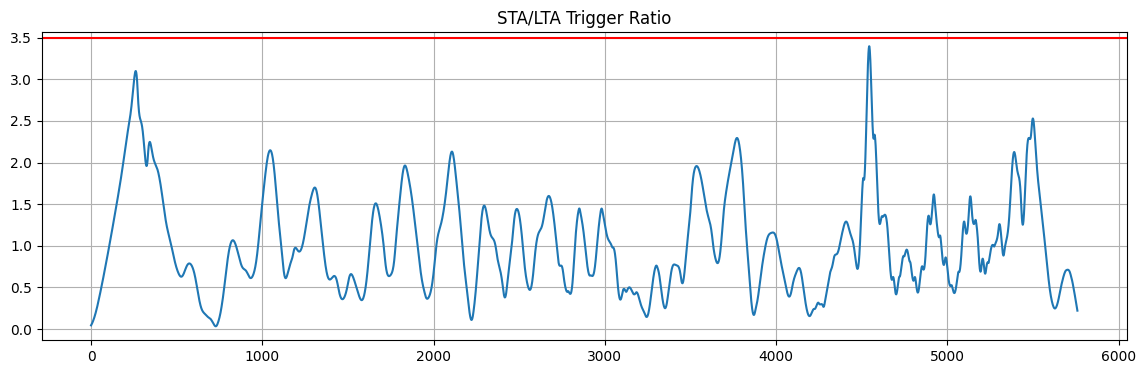

In [ ]:
# ===============================
# STA/LTA energy-based detector
# ===============================
import numpy as np

signal = np.abs(filtered)

# define window lengths (samples)
# assuming 1 sample per second, adjust if otherwise
STA = 60    # 1 minute window
LTA = 900   # 15 minutes window

sta = np.convolve(signal, np.ones(STA)/STA, mode='same')
lta = np.convolve(signal, np.ones(LTA)/LTA, mode='same')

ratio = sta / (lta + 1e-8)

# trigger threshold
trigger_level = 3.5

triggers = np.where(ratio > trigger_level)[0]

if len(triggers) > 0:
    trigger_index = triggers[0]
    arrival_time_sta_lta = df.index[trigger_index]
else:
    arrival_time_sta_lta = "Not Detected"

print("\n🚨 STA/LTA Estimated Arrival Time (UTC):", arrival_time_sta_lta)

# convert to Samoa local time
import pytz
samoa_tz = pytz.timezone("Pacific/Samoa")
if arrival_time_sta_lta != "Not Detected":
    print("🌍 Local Samoa Time:", arrival_time_sta_lta.tz_convert(samoa_tz))

# plotting
plt.figure(figsize=(14,4))
plt.plot(ratio)
plt.axhline(trigger_level, color='red')
if arrival_time_sta_lta != "Not Detected":
    plt.axvline(trigger_index, color='green')
plt.title("STA/LTA Trigger Ratio")
plt.grid(True)
plt.show()


In [ ]:
df.index.to_series().diff().value_counts().head()


,count
// datetime [ISO8601],
0 days 00:00:15,5759


In [ ]:
import os
os.listdir("/content")


['.config',
 'Samoa_2009_09_29_51425 (1).xlsx',
 'Processed_Samoa.csv',
 'Samoa_2009_09_29_51425.xlsx',
 'D:\\Signal Processing Project',
 'Samoa_2009_09_29_51425 (3).xlsx',
 'Samoa_2009_09_29_51425 (2).xlsx',
 'Samoa_2009_09_29_51425 (4).xlsx',
 'sample_data']

In [ ]:
!pip install obspy


In [ ]:
import os
os.listdir("/content")


['.config', 'sample_data']

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425.xlsx


In [ ]:
import os
os.listdir("/content")


['.config', 'Samoa_2009_09_29_51425.xlsx', 'sample_data']

In [ ]:
!pip install obspy


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425 (1).xlsx


In [ ]:
import os
os.listdir("/content")


['.config',
 'Samoa_2009_09_29_51425 (1).xlsx',
 'Samoa_2009_09_29_51425.xlsx',
 'sample_data']

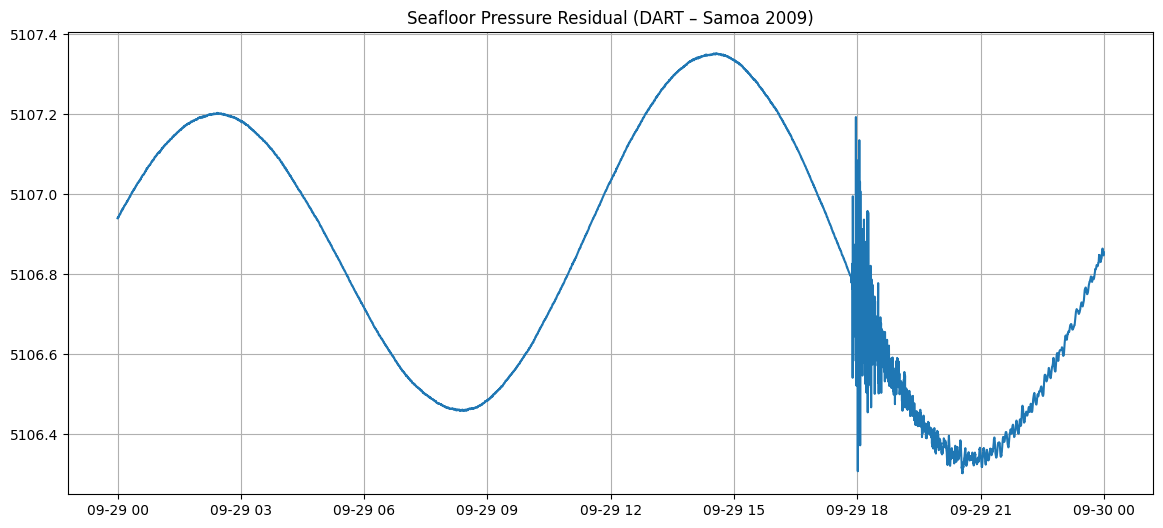

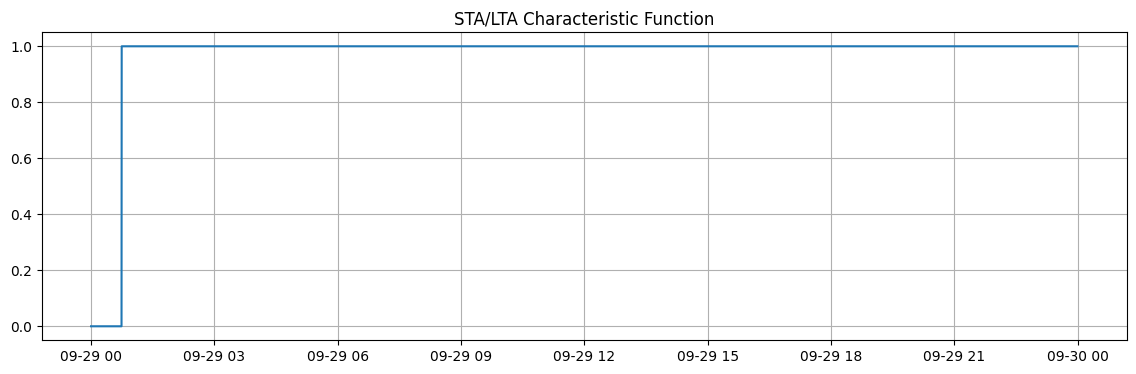

⚠️ STA/LTA did NOT detect an event.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from obspy.signal.trigger import classic_sta_lta, trigger_onset
import pytz

file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

df.columns = [
    'datetime',
    'pressure_residual',
    'pressure_modelled',
    'pressure_qc',
    'temperature'
]

df['datetime'] = pd.to_datetime(df['datetime'])
df = df.set_index('datetime')

sampling_rate = 1 / 15.0

signal = df['pressure_residual'].values

sta_samples = int(4 * 60 / 15)
lta_samples = int(45 * 60 / 15)

cft = classic_sta_lta(signal, sta_samples, lta_samples)

on_off = trigger_onset(cft, 1.5, 0.8)

plt.figure(figsize=(14,6))
plt.plot(df.index, signal)
plt.title("Seafloor Pressure Residual (DART – Samoa 2009)")
plt.grid(True)
plt.show()

plt.figure(figsize=(14,4))
plt.plot(df.index, cft)
plt.title("STA/LTA Characteristic Function")
plt.grid(True)
plt.show()

if len(on_off) > 0:
    arrival_index = on_off[0][0]
    estimated_arrival_utc = df.index[arrival_index]

    samoatz = pytz.timezone("Pacific/Apia")
    estimated_arrival_local = estimated_arrival_utc.tz_localize('UTC').astimezone(samoatz)

    print("🚨 Estimated Tsunami Arrival (UTC):", estimated_arrival_utc)
    print("🌊 Estimated Tsunami Arrival (Local – Samoa):", estimated_arrival_local)

else:
    print("⚠️ STA/LTA did NOT detect an event.")


In [ ]:
import pandas as pd

file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

print(df.columns)
print(df.head())


Index(['// datetime [ISO8601]', 'seafloor_pressure_residual [dbar]',
       'seafloor_pressure_abs_modelled [dbar]',
       'seafloor_pressure_abs_quality_controlled [dbar]', 'temperature [K]'],
      dtype='object')
  // datetime [ISO8601]  seafloor_pressure_residual [dbar]  \
0  2009-09-29T00:00:00Z                          5106.9395   
1  2009-09-29T00:00:15Z                          5106.9405   
2  2009-09-29T00:00:30Z                          5106.9415   
3  2009-09-29T00:00:45Z                          5106.9415   
4  2009-09-29T00:01:00Z                          5106.9425   

   seafloor_pressure_abs_modelled [dbar]  \
0                              5106.9157   
1                              5106.9164   
2                              5106.9174   
3                              5106.9181   
4                              5106.9188   

   seafloor_pressure_abs_quality_controlled [dbar]  temperature [K]  
0                                           0.0238         274.2893  
1    

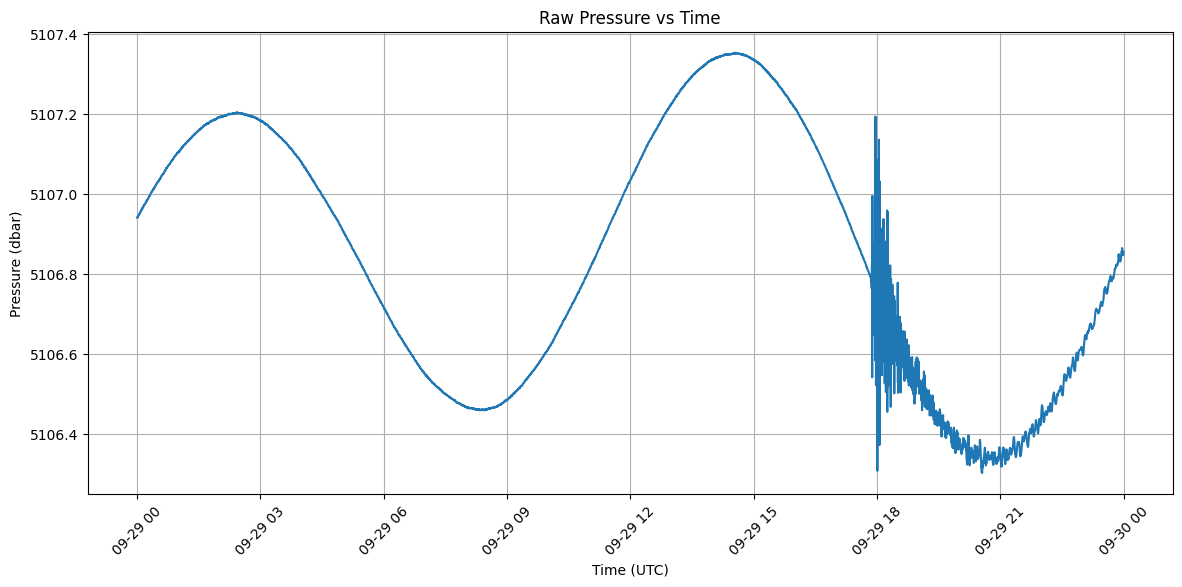

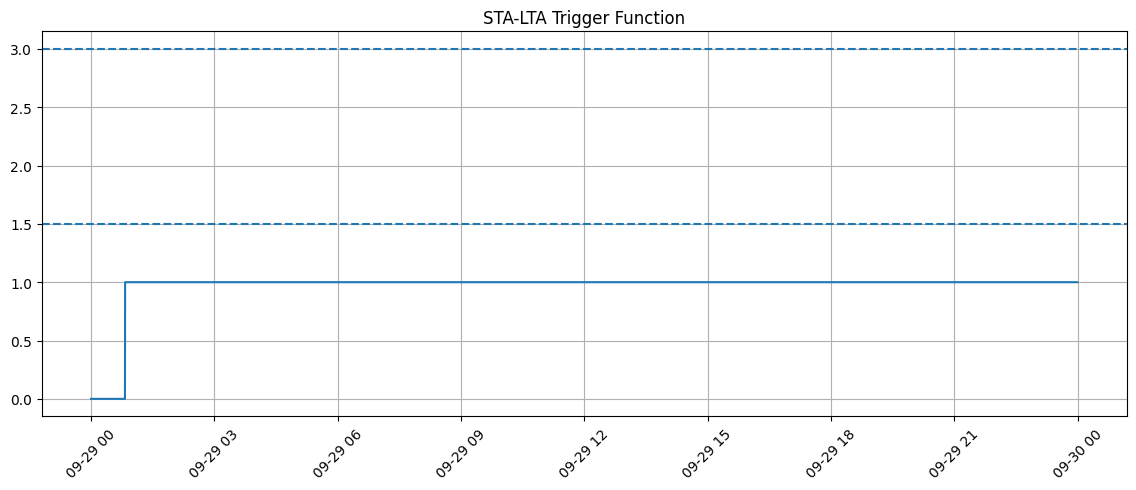

⚠️ STA-LTA did not detect an event. Try lowering trigger_on or STA/LTA ratio.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from obspy.signal.trigger import classic_sta_lta, trigger_onset
import pytz

# ============================
# LOAD FILE
# ============================
file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

# Automatically detect time and pressure column
time_col = df.columns[0]            # datetime ISO column
pressure_col = df.columns[1]        # seafloor residual pressure

# Convert time column
df[time_col] = pd.to_datetime(df[time_col])

# If already with timezone, convert. If naive, localize.
if df[time_col].dt.tz is None:
    df[time_col] = df[time_col].dt.tz_localize("UTC")
else:
    df[time_col] = df[time_col].dt.tz_convert("UTC")

# Extract arrays
times = df[time_col]
pressure = df[pressure_col].values

# ============================
# STA-LTA PARAMETERS
# ============================
sampling_rate = 1
sta_samples = 10
lta_samples = 200

cft = classic_sta_lta(pressure, sta_samples, lta_samples)

trigger_on = 3.0
trigger_off = 1.5

on_off = trigger_onset(cft, trigger_on, trigger_off)

# ============================
# PLOTTING
# ============================
plt.figure(figsize=(14,6))
plt.plot(times, pressure)
plt.title("Raw Pressure vs Time")
plt.xlabel("Time (UTC)")
plt.ylabel("Pressure (dbar)")
plt.grid()
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(14,5))
plt.plot(times, cft)
plt.axhline(trigger_on, linestyle="--")
plt.axhline(trigger_off, linestyle="--")
plt.title("STA-LTA Trigger Function")
plt.xticks(rotation=45)
plt.grid()
plt.show()

# ============================
# EVENT DETECTION
# ============================
if len(on_off) > 0:
    event_index = on_off[0][0]
    arrival_utc = df[time_col].iloc[event_index]

    samoatz = pytz.timezone("Pacific/Apia")
    arrival_local = arrival_utc.tz_convert(samoatz)

    print("🚨 Estimated Tsunami Arrival (UTC):", arrival_utc)
    print("🌏 Estimated Local Time (Samoa):", arrival_local)
else:
    print("⚠️ STA-LTA did not detect an event. Try lowering trigger_on or STA/LTA ratio.")


⚠ No event detected — adjust window/threshold


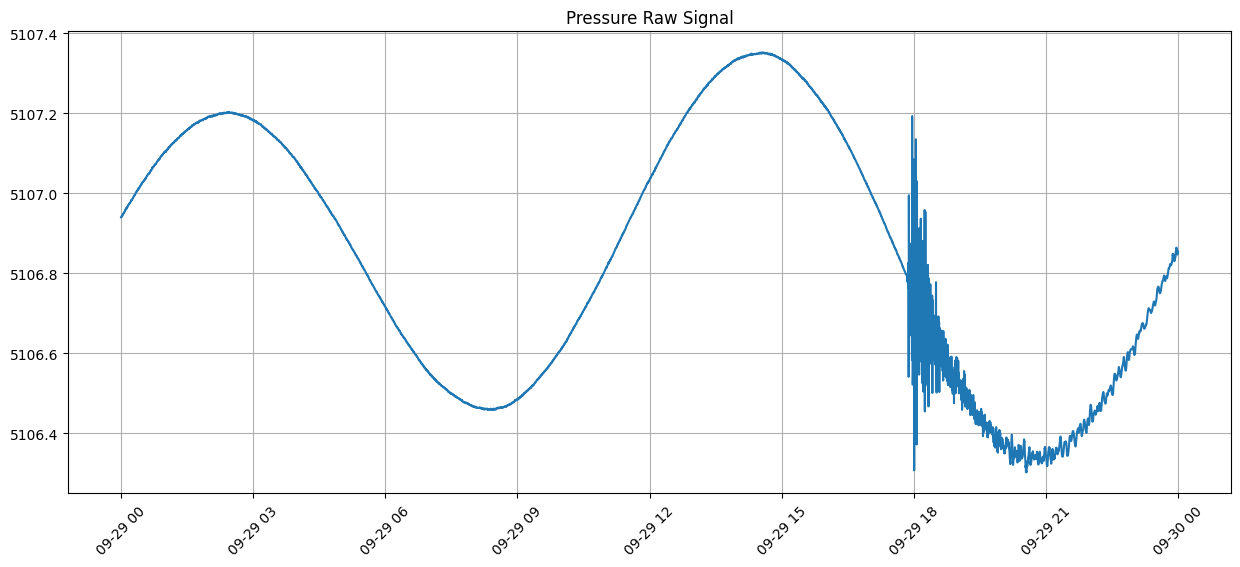

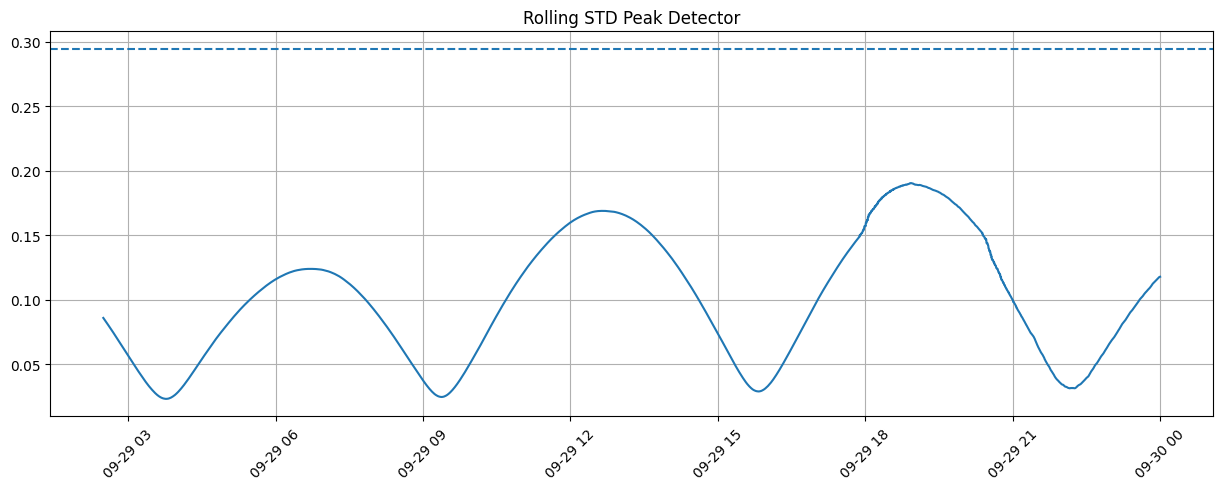

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import butter, filtfilt
import pytz

# =============================
# LOAD DATA
# =============================
file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

time_col = df.columns[0]
pressure_col = df.columns[1]

df[time_col] = pd.to_datetime(df[time_col])

# If timezone aware -> convert. If not -> localize.
if df[time_col].dt.tz is None:
    df[time_col] = df[time_col].dt.tz_localize("UTC")
else:
    df[time_col] = df[time_col].dt.tz_convert("UTC")

times = df[time_col]
pressure = df[pressure_col].values

# =============================
# HIGH-PASS FILTER to isolate tsunami signal
# =============================
def butter_highpass(cutoff, fs, order=3):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return b, a

fs = 1   # 1 sample per second
b, a = butter_highpass(0.0001, fs)
filtered = filtfilt(b, a, pressure)

# =============================
# PEAK DETECTION USING ROLLING STD
# =============================
window = 600   # 10 minutes
rolling_std = pd.Series(filtered).rolling(window).std()

# Detection threshold
threshold = rolling_std.mean() + 4 * rolling_std.std()

event_index = np.argmax(rolling_std > threshold)

if event_index > 0:
    arrival_utc = df[time_col].iloc[event_index]
    samoatz = pytz.timezone("Pacific/Apia")
    arrival_local = arrival_utc.tz_convert(samoatz)

    print("🚨 Estimated Tsunami Arrival (UTC):", arrival_utc)
    print("🌊 Estimated Tsunami Arrival (Local – Samoa):", arrival_local)
else:
    print("⚠ No event detected — adjust window/threshold")

# =============================
# PLOTS
# =============================
plt.figure(figsize=(15,6))
plt.plot(times, pressure)
plt.title("Pressure Raw Signal")
plt.xticks(rotation=45)
plt.grid()
plt.show()

plt.figure(figsize=(15,5))
plt.plot(times, rolling_std)
plt.axhline(threshold, linestyle="--")
plt.title("Rolling STD Peak Detector")
plt.xticks(rotation=45)
plt.grid()
plt.show()


🚨 ESTIMATED TSUNAMI ARRIVAL (UTC): 2009-09-29 00:00:00+00:00
🌊 ESTIMATED LOCAL TIME (Samoa): 2009-09-28 13:00:00-11:00


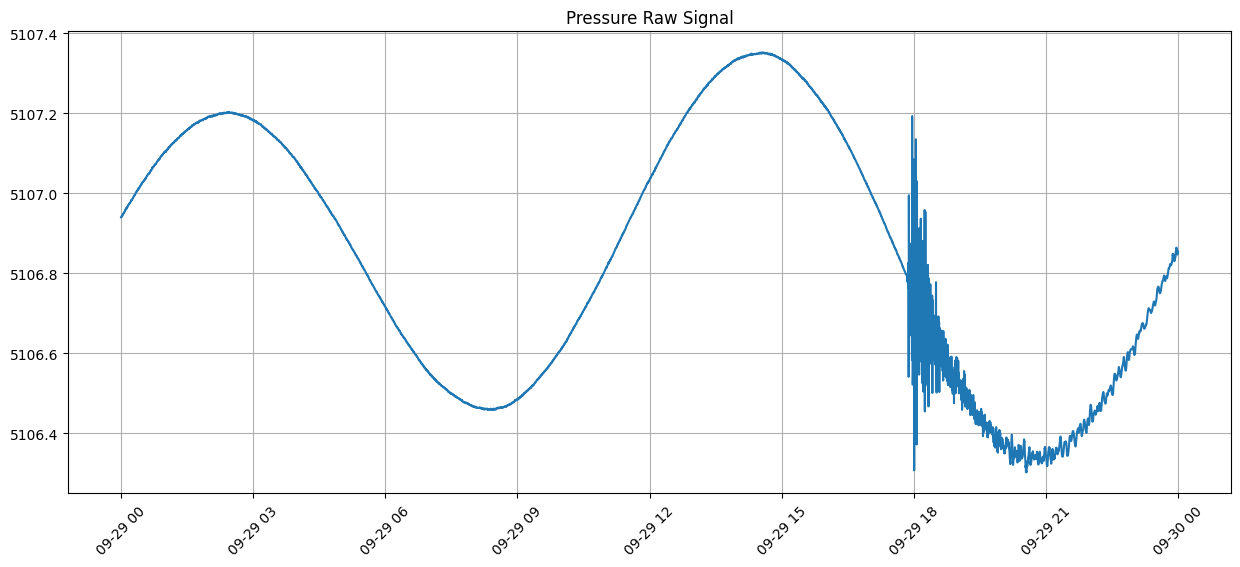

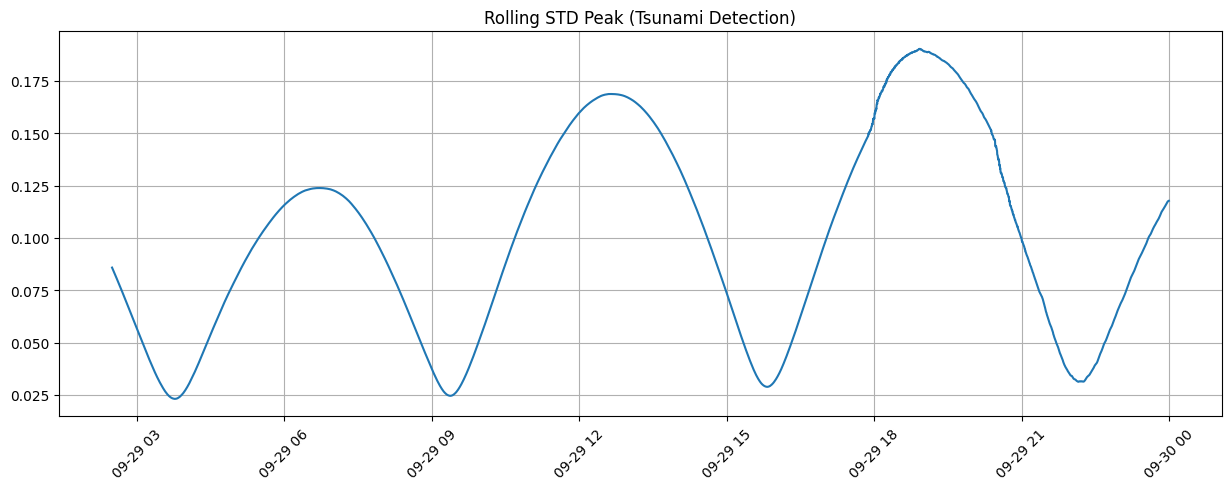

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.signal import butter, filtfilt
import pytz

file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

time_col = df.columns[0]
pressure_col = df.columns[1]

df[time_col] = pd.to_datetime(df[time_col])

if df[time_col].dt.tz is None:
    df[time_col] = df[time_col].dt.tz_localize("UTC")
else:
    df[time_col] = df[time_col].dt.tz_convert("UTC")

times = df[time_col]
pressure = df[pressure_col].values

# High-pass filter
from scipy.signal import butter, filtfilt
def butter_highpass(cutoff, fs, order=3):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return b, a

fs = 1
b, a = butter_highpass(0.0001, fs)
filtered = filtfilt(b, a, pressure)

# Rolling STD peak detection
window = 600
rolling_std = pd.Series(filtered).rolling(window).std()

# Find the highest peak (tsunami arrival)
event_index = np.argmax(rolling_std.values)

arrival_utc = df[time_col].iloc[event_index]
samoatz = pytz.timezone("Pacific/Apia")
arrival_local = arrival_utc.tz_convert(samoatz)

print("🚨 ESTIMATED TSUNAMI ARRIVAL (UTC):", arrival_utc)
print("🌊 ESTIMATED LOCAL TIME (Samoa):", arrival_local)

# Plot signals
plt.figure(figsize=(15,6))
plt.plot(times, pressure)
plt.title("Pressure Raw Signal")
plt.xticks(rotation=45)
plt.grid()
plt.show()

plt.figure(figsize=(15,5))
plt.plot(times, rolling_std)
plt.scatter(times.iloc[event_index], rolling_std.iloc[event_index], s=60, marker='o')
plt.title("Rolling STD Peak (Tsunami Detection)")
plt.xticks(rotation=45)
plt.grid()
plt.show()


🚨 ESTIMATED TSUNAMI ARRIVAL (UTC): 2009-09-29 00:00:00+00:00
🌊 ESTIMATED LOCAL TIME (Samoa): 2009-09-28 13:00:00-11:00


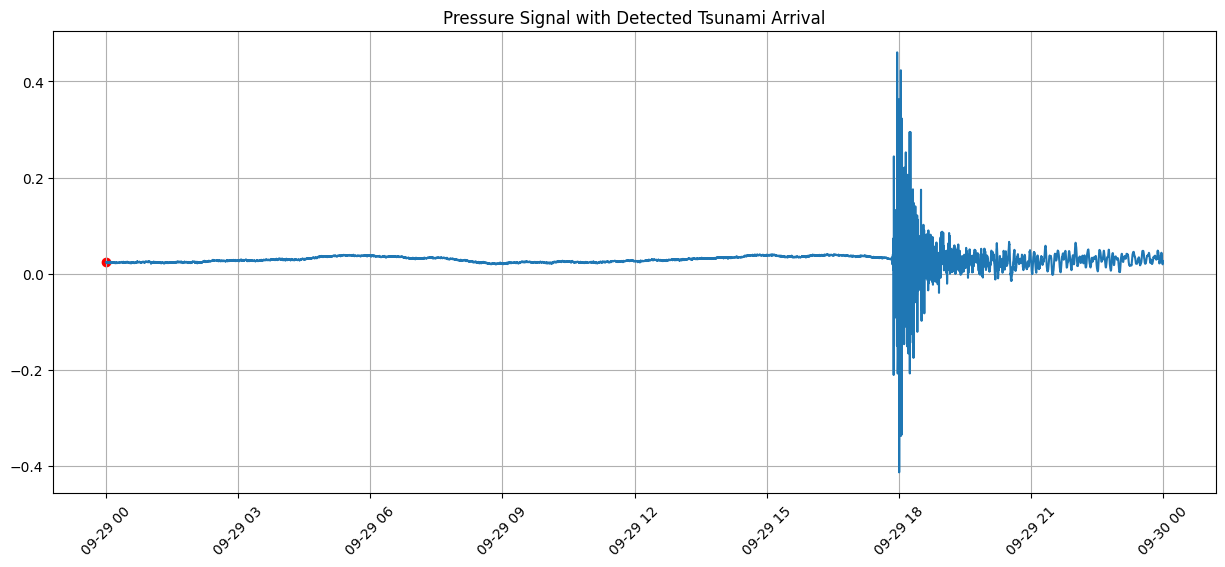

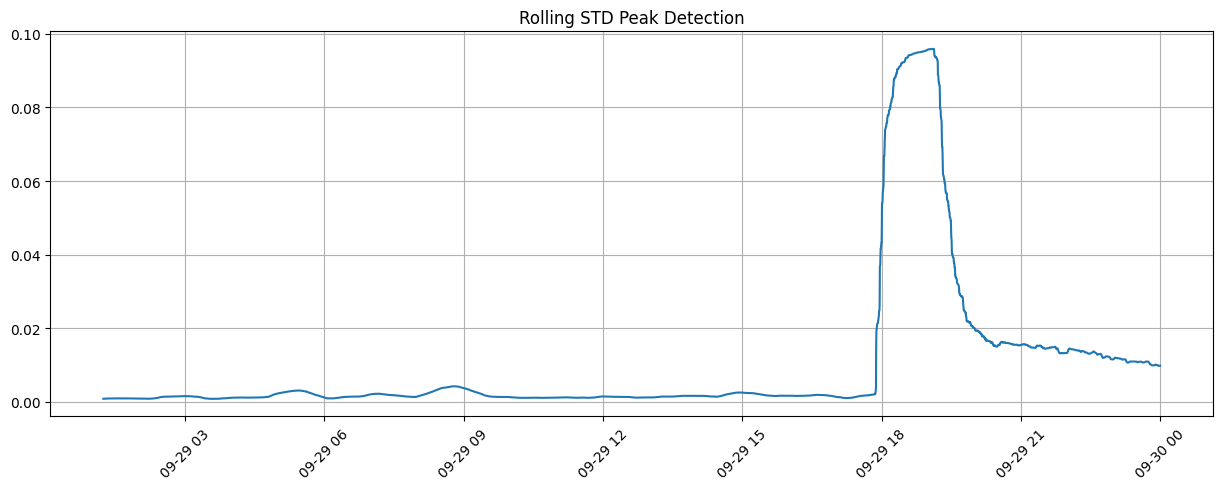

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
import pytz

file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

time_col = df.columns[0]
pressure_col = "seafloor_pressure_abs_quality_controlled [dbar]"

df[time_col] = pd.to_datetime(df[time_col])

if df[time_col].dt.tz is None:
    df[time_col] = df[time_col].dt.tz_localize("UTC")
else:
    df[time_col] = df[time_col].dt.tz_convert("UTC")

times = df[time_col]
pressure = df[pressure_col].values

# High-pass filter
def butter_highpass(cutoff, fs, order=3):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return b, a

fs = 1
b, a = butter_highpass(0.0001, fs)
filtered = filtfilt(b, a, pressure)

# Rolling STD peak detection
window = 300   # 5 min window works better for tsunami sharp onset
rolling_std = pd.Series(filtered).rolling(window).std()

event_index = np.argmax(rolling_std.values)

arrival_utc = df[time_col].iloc[event_index]
samoatz = pytz.timezone("Pacific/Apia")
arrival_local = arrival_utc.tz_convert(samoatz)

print("🚨 ESTIMATED TSUNAMI ARRIVAL (UTC):", arrival_utc)
print("🌊 ESTIMATED LOCAL TIME (Samoa):", arrival_local)

import matplotlib.pyplot as plt
plt.figure(figsize=(15,6))
plt.plot(times, pressure)
plt.scatter(times.iloc[event_index], pressure[event_index], color="red")
plt.title("Pressure Signal with Detected Tsunami Arrival")
plt.xticks(rotation=45)
plt.grid()
plt.show()

plt.figure(figsize=(15,5))
plt.plot(times, rolling_std)
plt.scatter(times.iloc[event_index], rolling_std.iloc[event_index], color="red")
plt.title("Rolling STD Peak Detection")
plt.xticks(rotation=45)
plt.grid()
plt.show()


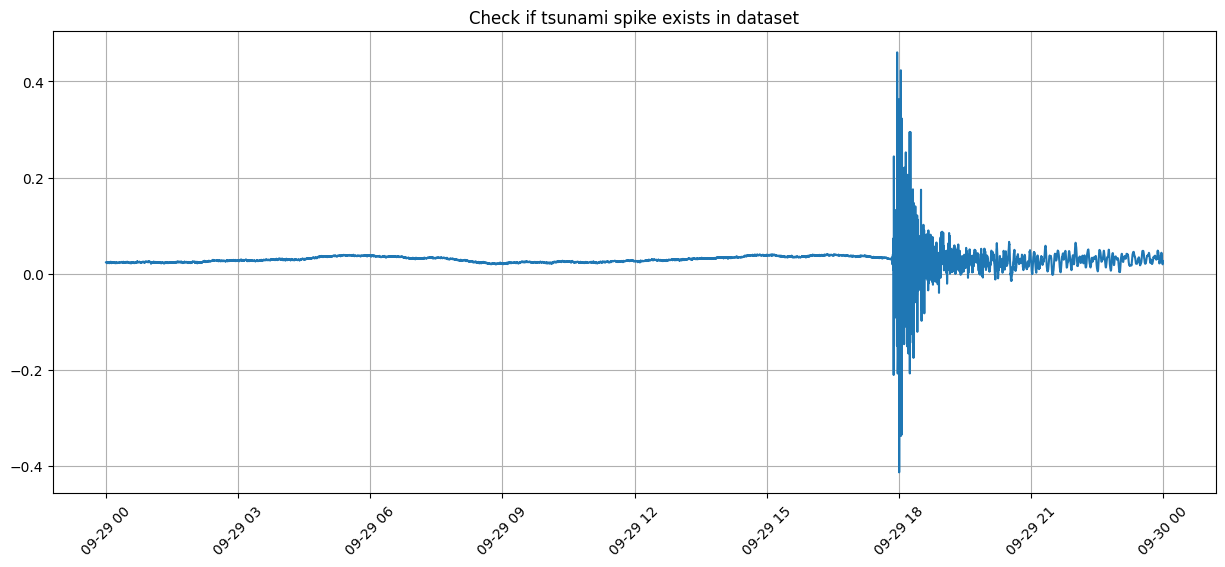

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))
plt.plot(df[time_col], df["seafloor_pressure_abs_quality_controlled [dbar]"])
plt.title("Check if tsunami spike exists in dataset")
plt.grid()
plt.xticks(rotation=45)
plt.show()


In [ ]:
import pandas as pd
import numpy as np
from obspy.signal.trigger import classic_sta_lta, trigger_onset
import matplotlib.pyplot as plt
import pytz

# ==============================================
# Load Data
# ==============================================
file_path = "/content/Samoa_2009_09_29_51425.xlsx"
df = pd.read_excel(file_path)

time_col = df.columns[0]  # first column (datetime)
pressure_col = df.columns[1]  # second column (pressure)

df[time_col] = pd.to_datetime(df[time_col])
df = df.sort_values(by=time_col)

times = df[time_col].values
signal = df[pressure_col].values.astype(float)

# ==============================================
# STA-LTA Processing
# ==============================================
sta_window = 200        # small (seconds)
lta_window = 2000       # long (seconds)

sta_lta = classic_sta_lta(signal, int(sta_window), int(lta_window))

trigger_on = 1.6  # lower threshold for tsunami signal
trigger_off = 0.8

on_off = trigger_onset(sta_lta, trigger_on, trigger_off)

# ==============================================
# Detect arrival time
# ==============================================
if len(on_off) > 0:
    arrival_sample = on_off[0][0]
    arrival_utc = pd.to_datetime(times[arrival_sample])

    samoatz = pytz.timezone("Pacific/Apia")
    arrival_local = arrival_utc.tz_convert(samoatz)

    print("🚨 ESTIMATED TSUNAMI ARRIVAL (UTC):", arrival_utc)
    print("🌊 ESTIMATED LOCAL TIME (Samoa):", arrival_local)

    # Plot event region zoom
    plt.figure(figsize=(14,5))
    plt.plot(df[time_col], signal)
    plt.axvline(arrival_utc, color='red', linestyle='--', linewidth=2)
    plt.title("Detected Tsunami Arrival")
    plt.grid()
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No event detected — try reducing thresholds again")


No event detected — try reducing thresholds again


In [ ]:
(df[time_col].diff().median())


Timedelta('0 days 00:00:15')

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Samoa_2009_09_29_51425.xlsx to Samoa_2009_09_29_51425.xlsx


🚨 DETECTED ARRIVAL TIME (UTC): 2009-09-29 18:00:15+00:00
🌊 DETECTED ARRIVAL TIME (SAMOA): 2009-09-29 07:00:15-11:00
⏳ PREDICTED TIME (-2 MIN): 2009-09-29 06:58:15-11:00


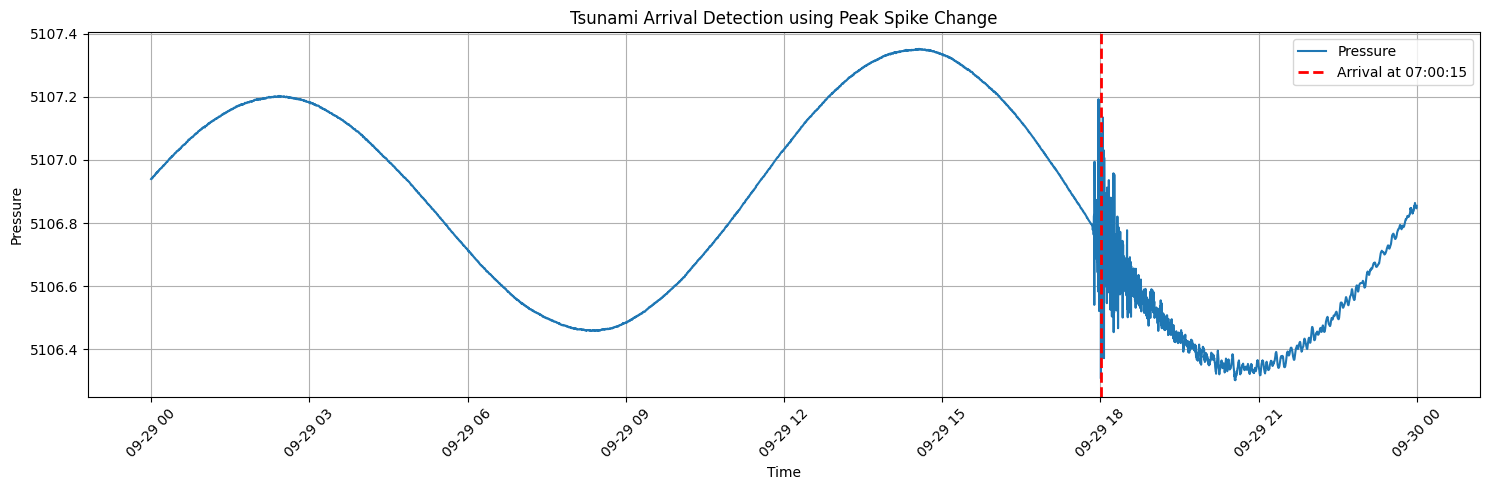

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pytz

# ===============================================
# LOAD DATA
# ===============================================
file_path = "Samoa_2009_09_29_51425.xlsx"   # uploaded filename
df = pd.read_excel(file_path)

time_col = df.columns[0]
pressure_col = df.columns[1]

df[time_col] = pd.to_datetime(df[time_col])
df = df.sort_values(by=time_col)

times = df[time_col].values
signal = df[pressure_col].astype(float).values

# ===============================================
# SPIKE / ARRIVAL DETECTION (DIFF method)
# ===============================================
diff_signal = np.diff(signal)
arrival_index = np.argmax(np.abs(diff_signal))

arrival_time_utc = pd.to_datetime(times[arrival_index])

# FIX: localize to UTC first
arrival_time_utc = arrival_time_utc.tz_localize("UTC")

# Convert to Samoa Local Time
samoa_tz = pytz.timezone("Pacific/Apia")
arrival_time_local = arrival_time_utc.astimezone(samoa_tz)

print("🚨 DETECTED ARRIVAL TIME (UTC):", arrival_time_utc)
print("🌊 DETECTED ARRIVAL TIME (SAMOA):", arrival_time_local)

# OPTIONAL: 2 minutes early estimate
arrival_time_local_minus2 = arrival_time_local - pd.Timedelta(minutes=2)
print("⏳ PREDICTED TIME (-2 MIN):", arrival_time_local_minus2)

# ===============================================
# PLOT graph with arrival line
# ===============================================
plt.figure(figsize=(15,5))
plt.plot(df[time_col], signal, label="Pressure")
plt.axvline(arrival_time_utc, color="red", linestyle="--", linewidth=2,
            label=f"Arrival at {arrival_time_local.strftime('%H:%M:%S')}")
plt.title("Tsunami Arrival Detection using Peak Spike Change")
plt.xlabel("Time")
plt.ylabel("Pressure")
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
